# Klasifikasi Komentar Dengan Naive Bayes
---

## 1. Business Understading

### 1.1 Latar belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah perusahaan platform media sosial yang ingin mengelompokkan komentar pada platformnya secara otomatis berdasarkan topik pembahasan secara otomatis dan cepat.
2. **Masalah**: Proses pengelompokan ribuan data teks secara manual membutuhkan waktu yang sangat lamadan rentan mengalami kesalahan penilaiansubjektif.
3. **Solusi**: Membuat model *machine learning* dengan algoritma **Naive Bayes** untuk memprediksi kategori topik secara otomatis berdasarkan pola kemunculan kata.

### 1.2 Deskripsi Kolom Dataset `dataset_penyisihan_bdc_2024.csv`

| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :-- |
| `text` | `str` | teks komentar media sosial |
| `label` | `str` | jenis pembahasan dari komentar |


---
## 2. Data Preparation

### 2.1 Import library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [2]:
df = pd.read_csv('dataset_penyisihan_bdc_2024.csv', sep=';', na_values=['NA', 'N/A', 'NaN'])
df.columns = df.columns.str.strip()

### 2.3 Menampikan data teratas dan data terbawah

In [3]:
df.head()

,text,label
0,Kunjungan Prabowo ini untuk meresmikan dan men...,Sumber Daya Alam
1,RT Anies dapat tepuk tangan meriah saat jadi R...,Politik
2,@CIqXqwGAT04tMtx4OCATxjoVq7vv/Y8HeYaIOgMFg8Y= ...,Demografi
3,RT @L3R8XFBw3WGbxRPSj0/0hHZTbqVGX7qtfwRg9zmhK7...,Politik
4,Anies Baswedan Harap ASN termasuk TNI dan Polr...,Politik


In [4]:
df.tail()

,text,label
4995,RT @l1DsGGe2xObT3t72dHwqlT58X7jvEYtEnauZIZSYwS...,Politik
4996,Masyarakat yakin bahwa Prabowo-Gibran memiliki...,Politik
4997,imo both are irrational but yg satu jauh lebih...,Ekonomi
4998,@cIIGSdjaPrmAQY1E4gWnLpIZSdyQn8ZMhjJzgOsxfRM= ...,Pertahanan dan Keamanan
4999,"Acara ini tidak hanya memasak, tetapi Calon Pr...",Sumber Daya Alam


### 2.4 Memeriksa informasi data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5000 non-null   str  
 1   label   5000 non-null   str  
dtypes: str(2)
memory usage: 78.3 KB


### 2.5 Memriksa jumlah data, missing value, dan data duplikat

In [6]:
print(f'Jumlah data: {df.size}')

print(f'jumlah missing value: {df.isnull().sum().sum()}')
duplicated = df.duplicated().sum()
duplicated_text = df.duplicated(subset=['text']).sum()

print("Duplikat identik:", duplicated)
print("Duplikat berdasarkan teks:", duplicated_text)


Jumlah data: 10000
jumlah missing value: 0
Duplikat identik: 381
Duplikat berdasarkan teks: 417


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [7]:
df.describe()

,text,label
count,5000,5000
unique,4583,8
top,RT Abah Anies ingin mengangkat martabat petani...,Politik
freq,42,2972


### 3.2 Analisiss distribusi data label

In [8]:
kelas = df['label'].value_counts()
persentase_kelas = df['label'].value_counts(normalize=True) * 100

distribusi_target = pd.DataFrame({
    'jumlah data': kelas,
    'persentase (%)': persentase_kelas.round(2)
})

print(distribusi_target)

                         jumlah data  persentase (%)
label                                               
Politik                         2972           59.44
Sosial Budaya                    587           11.74
Pertahanan dan Keamanan          400            8.00
Ideologi                         400            8.00
Ekonomi                          367            7.34
Sumber Daya Alam                 192            3.84
Demografi                         62            1.24
Geografi                          20            0.40


### 3.3 Visualisasi distribusi label

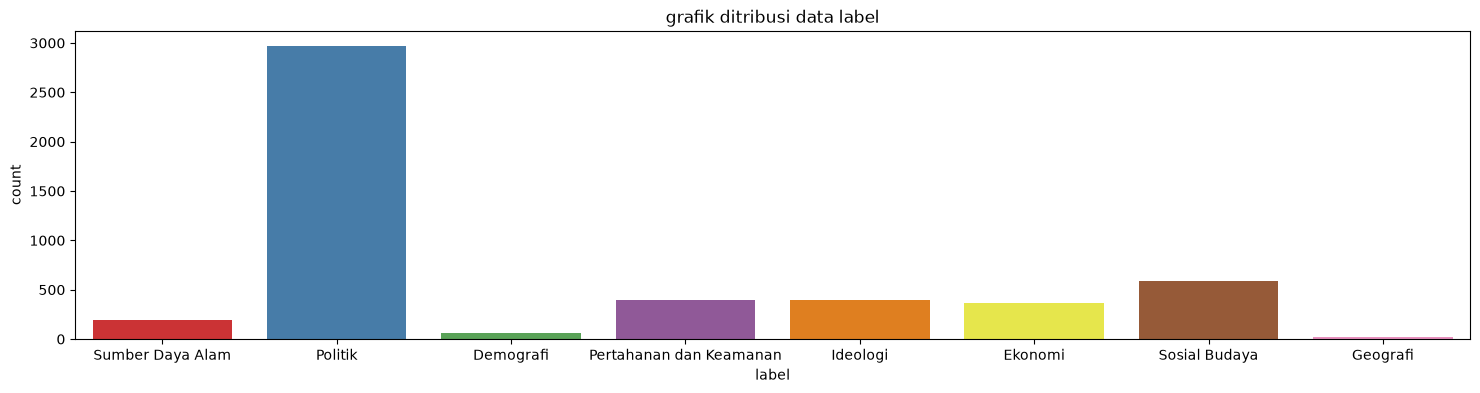

In [9]:
plt.figure(figsize=(18,4))
sns.countplot(data=df, x='label', palette='Set1', hue='label',legend=False)
plt.title('grafik ditribusi data label')
plt.show()

**Insight**: Grafik menunjukkan ketidakseimbangan kelas yang sangat ekstrem karena kategori Politik mendominasi hampir 3.000 data sementara kategori seperti Geografi dan Demografi berjumlah sangat sedikit, sehingga diperlukan pembagian data secara stratified serta penerapan teknik penyeimbangan sampel (*oversampling*) agar model tidak bias terhadap kelas mayoritas.

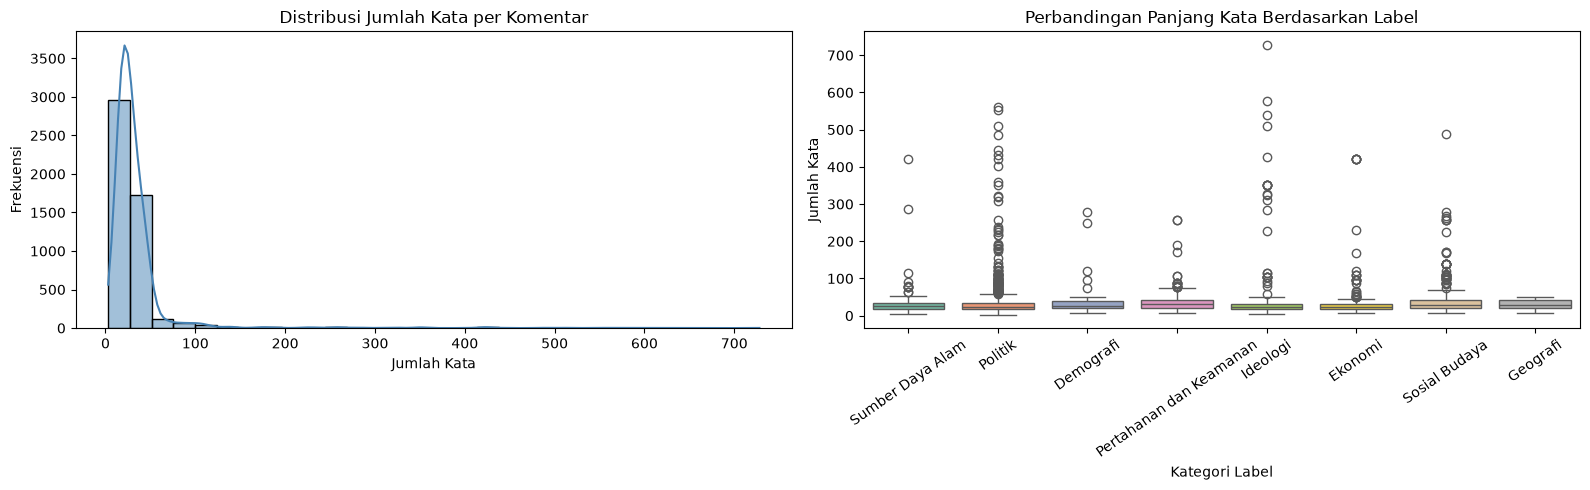

In [10]:
jumlah_kata = df['text'].astype(str).str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(jumlah_kata, bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Jumlah Kata per Komentar')
axes[0].set_xlabel('Jumlah Kata')
axes[0].set_ylabel('Frekuensi')
    
sns.boxplot(x=df['label'], y=jumlah_kata, ax=axes[1], palette='Set2', hue=df['label'], legend=False)
axes[1].set_title('Perbandingan Panjang Kata Berdasarkan Label')
axes[1].set_xlabel('Kategori Label')
axes[1].set_ylabel('Jumlah Kata')
axes[1].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()

**Insight**: Mayoritas komentar pada seluruh kategori didominasi oleh kalimat singkat dengan panjang berkisar antara 10 hingga 50 kata, meskipun terdapat banyak pencilan (*outliers*) berupa teks panjang hingga lebih dari 700 kata pada kategori Ideologi dan Politik.

---
## 4. Data Preprocessing

### 4.1 Menangani data duplikat identik

In [11]:
df = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f'sisa baris seletah menghapus data duplikat identik: {len(df)}')

sisa baris seletah menghapus data duplikat identik: 4619


### 4.2 Menangani data dupliakt pada kolom `text`

In [12]:
df = df.drop_duplicates(subset=['text'], keep=False).reset_index(drop=True)

print("Sisa baris yang benar-benar unik:", len(df))

Sisa baris yang benar-benar unik: 4547


### 4.3 Pembersihan teks

Tahap ini dilakukan untuk menghilangkan karakter tidak relevan seperti tautan, tanda baca, dan atribut media sosial agar tidak mengganggu proses ekstrak kata kunci.

In [13]:
def clean_caracter (teks):
    teks = teks.lower()
    
    list_teks = teks.split()
    kata_tersaring = []
    
    tag_re = False
    for kata in list_teks:
        if kata.startswith('[re'):
            tag_re = True
            continue
        if tag_re:
            if kata.endswith(']'):
                tag_re = False
            continue
        
        if kata == 'rt' or kata.startswith('@') or kata.startswith('http') or kata.startswith('www'):
            continue
        
        kata_tersaring.append(kata)
    
    teks_sementara = ' '.join(kata_tersaring)
    
    karakter_valid = [huruf if ('a' <= huruf <= 'z') or huruf == ' ' else ' ' for huruf in teks_sementara]
    
    return ' '.join(''.join(karakter_valid).split())

df['text_clean'] = df['text'].apply(clean_caracter)

df['text_clean'] = df['text_clean'].replace('', np.nan)
df = df.dropna(subset=['text_clean']).reset_index(drop=True)

print("Sisa baris setelah pembersihan karakter:", len(df))

Sisa baris setelah pembersihan karakter: 4538


### 4.4 Normalisasi kata yang tidak baku

Metode ini diterapkan untuk menyeragamkan variasi bahasa gaul menjadi kata baku sekaligus membuang kata hubung umum yang tidak memiliki nilai pembeda antar topik.

In [14]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

factory_stopword = StopWordRemoverFactory()
stopwords_id = set(factory_stopword.get_stop_words())

kamus = {
    'yg': 'yang', 'jg': 'juga', 'dg': 'dengan', 'dgn': 'dengan',
    'emng': 'memang', 'engga': 'tidak', 'gak': 'tidak', 'ga': 'tidak',
    'skrg': 'sekarang', 'sj': 'saja', 'klo': 'kalau', 'bgt': 'banget',
    'utk': 'untuk', 'dlm': 'dalam', 'pd': 'pada', 'sdh': 'sudah',
    'hnya': 'hanya', 'tdk': 'tidak', 'krn': 'karena', 'tp': 'tapi'
}

def saring_kata_umum(teks):
    daftar_kata = teks.split()
    hasil = []
    
    for kata in daftar_kata:
        kata = kamus.get(kata, kata)
        
        if kata not in stopwords_id and len(kata) > 2:
            hasil.append(kata)
            
    return ' '.join(hasil)

df['text_clean'] = df['text_clean'].apply(saring_kata_umum)
print(df['text_clean'].head())

0    kunjungan prabowo meresmikan menyerahkan proye...
1    anies tepuk tangan meriah jadi rektor mewajibk...
2    memang bener sih pendukung goblok pendukung pa...
3    sewaktu anies bersikap kritis kinerja pak prab...
4    anies baswedan harap asn termasuk tni polri pe...
Name: text_clean, dtype: str


### 4.5 Merubah kata berhimbuhan menjadi kata dasar

Proses ini digunakan untuk menyatukan berbagai bentuk kata berimbuhan ke akar katanya sehingga dimensi kosakata menjadi lebih ringkas dan terfokus.

In [15]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
kamus_stemming = {}

def ubah_kata_dasar(teks):
    daftar_kata = teks.split()
    hasil = []
    
    for kata in daftar_kata:
        if kata not in kamus_stemming:
            kamus_stemming[kata] = stemmer.stem(kata)
            
        kata_dasar = kamus_stemming[kata]
        if len(kata_dasar) > 2:
            hasil.append(kata_dasar)
            
    return ' '.join(hasil)

df['text_clean'] = df['text_clean'].apply(ubah_kata_dasar)

df['text_clean'] = df['text_clean'].replace('', np.nan)
df = df.dropna(subset=['text_clean']).reset_index(drop=True)

print(df[['text', 'text_clean']].head(5))

                                                text  \
0  Kunjungan Prabowo ini untuk meresmikan dan men...   
1  RT Anies dapat tepuk tangan meriah saat jadi R...   
2  @CIqXqwGAT04tMtx4OCATxjoVq7vv/Y8HeYaIOgMFg8Y= ...   
3  RT @L3R8XFBw3WGbxRPSj0/0hHZTbqVGX7qtfwRg9zmhK7...   
4  Anies Baswedan Harap ASN termasuk TNI dan Polr...   

                                          text_clean  
0  kunjung prabowo resmi serah proyek bantu air b...  
1  anies tepuk tangan riah jadi rektor wajib mata...  
2  memang bener sih dukung goblok dukung pak ridw...  
3  waktu anies sikap kritis kerja pak prabowo ang...  
4  anies baswedan harap asn masuk tni polri pegan...  


### 4.6 Pembagian data latih dan data uji (*Stratified Splitting*)

Metode ini dipilih untuk menjaga agar proporsi persentase setiap kelas pada data latih dan data uji tetap sama persis mengingat distribusi kategori pada dataset sangat tidak seimbang.

In [16]:
np.random.seed(42)
rasio_uji = 0.2

indeks_latih = []
indeks_uji = []

for label, kelompok in df.groupby('label'):
    daftar_indeks = kelompok.index.to_numpy(copy=True)
    np.random.shuffle(daftar_indeks)
    
    jumlah_uji = max(1, int(round(len(daftar_indeks) * rasio_uji)))
    
    indeks_uji.extend(daftar_indeks[:jumlah_uji])
    indeks_latih.extend(daftar_indeks[jumlah_uji:])

np.random.shuffle(indeks_latih)
np.random.shuffle(indeks_uji)

X_train = df.loc[indeks_latih, 'text_clean'].reset_index(drop=True)
y_train = df.loc[indeks_latih, 'label'].reset_index(drop=True)

X_test = df.loc[indeks_uji, 'text_clean'].reset_index(drop=True)
y_test = df.loc[indeks_uji, 'label'].reset_index(drop=True)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))
print("\nPersentase kategori pada data latih (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))
print("\nPersentase kategori pada data uji (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Jumlah data latih: 3630
Jumlah data uji: 908

Persentase kategori pada data latih (%):
label
Politik                    64.79
Sosial Budaya               8.98
Ideologi                    7.44
Pertahanan dan Keamanan     7.11
Ekonomi                     6.69
Sumber Daya Alam            3.25
Demografi                   1.32
Geografi                    0.41
Name: proportion, dtype: float64

Persentase kategori pada data uji (%):
label
Politik                    64.76
Sosial Budaya               8.92
Ideologi                    7.38
Pertahanan dan Keamanan     7.16
Ekonomi                     6.72
Sumber Daya Alam            3.30
Demografi                   1.32
Geografi                    0.44
Name: proportion, dtype: float64


### 4.7 Pembobotan kata dengan TF-IDF

Metode ini digunakan untuk mengubah teks menjadi representasi angka dengan memberikan bobot tinggi pada kata yang menjadi ciri khas suatu topik dan menurunkan bobot kata yang terlalu umum muncul di semua dokumen.

In [17]:
frekuensi_dokumen = {}

for kalimat in X_train:
    kata_unik = set(kalimat.split())
    for kata in kata_unik:
        frekuensi_dokumen[kata] = frekuensi_dokumen.get(kata, 0) + 1

maksimal_fitur = 5000
kata_terurut = sorted(frekuensi_dokumen.items(), key=lambda x: x[1], reverse=True)[:maksimal_fitur]

kamus_kata = {kata: indeks for indeks, (kata, _) in enumerate(kata_terurut)}

print("Total kosakata yang dipilih:", len(kamus_kata))

Total kosakata yang dipilih: 5000


### 4.8 Menghitung skor kelangkaan kata

In [18]:
jumlah_dokumen = len(X_train)
skor_idf = np.zeros(len(kamus_kata), dtype=np.float32)

for kata, indeks in kamus_kata.items():
    df_kata = frekuensi_dokumen[kata]
    # Rumus Smooth IDF standar
    skor_idf[indeks] = np.log((jumlah_dokumen + 1) / (df_kata + 1)) + 1

print("Contoh 5 nilai IDF pertama:", np.round(skor_idf[:5], 3))

Contoh 5 nilai IDF pertama: [1.996 2.03  2.078 2.548 2.561]


### 4.9 Mengubah Teks Latih dan Teks Uji Menjadi Matriks Angka TF-IDF

Tahap ini diterapkan pada perhitungan matriks TF-IDF agar perbedaan panjang kalimat antar komentar tidak mendominasi hasil perhitungan probabilitas model.

In [19]:
def ubah_ke_tfidf(kumpulan_teks, kamus_kata, skor_idf):
    matriks = np.zeros((len(kumpulan_teks), len(kamus_kata)), dtype=np.float32)
    
    for baris_ke, kalimat in enumerate(kumpulan_teks):
        daftar_kata = kalimat.split()
        if not daftar_kata:
            continue
            
        for kata in daftar_kata:
            if kata in kamus_kata:
                indeks_kolom = kamus_kata[kata]
                matriks[baris_ke, indeks_kolom] += 1.0
                
        matriks[baris_ke] = matriks[baris_ke] * skor_idf
        
        panjang_vektor = np.linalg.norm(matriks[baris_ke])
        if panjang_vektor > 0:
            matriks[baris_ke] = matriks[baris_ke] / panjang_vektor
            
    return matriks

X_train_tfidf = ubah_ke_tfidf(X_train, kamus_kata, skor_idf)
X_test_tfidf = ubah_ke_tfidf(X_test, kamus_kata, skor_idf)

print("Ukuran matriks data latih:", X_train_tfidf.shape)
print("Ukuran matriks data uji:", X_test_tfidf.shape)

Ukuran matriks data latih: (3630, 5000)
Ukuran matriks data uji: (908, 5000)


### 4.10 Implementasi random oversampling

In [20]:
np.random.seed(42)

kelas_unik, jumlah_per_kelas = np.unique(y_train, return_counts=True)
jumlah_maksimal = jumlah_per_kelas.max()

indeks_hasil_oversampling = []

for kelas in kelas_unik:
    indeks_kelas = np.where(y_train == kelas)[0]
    
    indeks_tambahan = np.random.choice(
        indeks_kelas, 
        size=jumlah_maksimal, 
        replace=True
    )
    indeks_hasil_oversampling.extend(indeks_tambahan)

indeks_hasil_oversampling = np.array(indeks_hasil_oversampling)
np.random.shuffle(indeks_hasil_oversampling)

X_train_balanced = X_train_tfidf[indeks_hasil_oversampling]
y_train_balanced = y_train.iloc[indeks_hasil_oversampling].reset_index(drop=True)

print("Ukuran matriks data latih setelah oversampling:", X_train_balanced.shape)
print("\nJumlah data per kategori setelah oversampling:")
print(y_train_balanced.value_counts())

Ukuran matriks data latih setelah oversampling: (18816, 5000)

Jumlah data per kategori setelah oversampling:
label
Geografi                   2352
Demografi                  2352
Pertahanan dan Keamanan    2352
Ideologi                   2352
Ekonomi                    2352
Politik                    2352
Sumber Daya Alam           2352
Sosial Budaya              2352
Name: count, dtype: int64


---

## 5. Modelling

### 5.1 Implementasi Algoritma Naive Bayes Multinomial

In [46]:
class NaiveBayes:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        self._classes = np.unique(y)
        n_data, n_fitur = X.shape
        n_kelas = len(self._classes)

        self.prior_log = np.zeros(n_kelas)
        self.likelihood_log = np.zeros((n_kelas, n_fitur))

        for i, c in enumerate(self._classes):
            X_c = X[y == c]
            self.prior_log[i] = np.log(len(X_c) / n_data)

            jumlah_kata = X_c.sum(axis=0) + self.alpha
            total_kata = X_c.sum() + (self.alpha * n_fitur)
            self.likelihood_log[i] = np.log(jumlah_kata / total_kata)

    def _hitung_skor(self, x):
        return self.prior_log + np.dot(self.likelihood_log, x)

    def predict(self, X):
        hasil = []
        for x in X:
            skor = self._hitung_skor(x)
            hasil.append(self._classes[np.argmax(skor)])
        return np.array(hasil)

    def predict_probabilities(self, X):
        semua_prob = []
        for x in X:
            skor = self._hitung_skor(x)
            exp_skor = np.exp(skor - np.max(skor))
            semua_prob.append(exp_skor / np.sum(exp_skor))
        return np.array(semua_prob)

### 5.2 Pelatihan Model

In [49]:
naive_bayes = NaiveBayes(alpha=1.0)
naive_bayes.fit(X_train_balanced, y_train_balanced)

jumlah_dok = [np.sum(y_train == c) for c in naive_bayes._classes]
prior = np.round(np.exp(naive_bayes.prior_log), 4)
bobot_kata = [round(X_train_balanced[y_train_balanced == c].sum(), 2) for c in naive_bayes._classes]

print("Jumlah Kelas Unik :", len(naive_bayes._classes), "kelas")
print("Ukuran Vocabulary :", X_train_balanced.shape[1], "fitur\n")

Jumlah Kelas Unik : 8 kelas
Ukuran Vocabulary : 5000 fitur



### 5.3 Prediksi Model pada Data Latih dan Data Uji

In [52]:
y_pred_train = naive_bayes.predict(X_train_tfidf)
y_pred_test = naive_bayes.predict(X_test_tfidf)
y_prob_test = naive_bayes.predict_probabilities(X_test_tfidf)

keyakinan = np.round(np.max(y_prob_test[:5], axis=1) * 100, 2)

hasil_prediksi = pd.DataFrame({'Label Aktual': y_test[:5], 'Hasil Prediksi': y_pred_test[:5], 'Keyakinan Model (%)': keyakinan})

print("5 Hasil Prediksi pada Data Uji:")
print(hasil_prediksi)

5 Hasil Prediksi pada Data Uji:
              Label Aktual           Hasil Prediksi  Keyakinan Model (%)
0                 Ideologi                  Politik                31.78
1            Sosial Budaya            Sosial Budaya                48.79
2                  Ekonomi            Sosial Budaya                61.11
3  Pertahanan dan Keamanan  Pertahanan dan Keamanan                52.66
4                  Politik                  Ekonomi                25.62


---

## 6. Evaluation

### 6.1 Implementasi Fungsi Evaluasi Multiclass

In [53]:
def hitung_evaluasi(y_asli, y_prediksi, daftar_kelas):
    y_asli = np.array(y_asli)
    y_prediksi = np.array(y_prediksi)
    jumlah_kelas = len(daftar_kelas)

    cm = np.zeros((jumlah_kelas, jumlah_kelas), dtype=int)
    for i, aktual in enumerate(daftar_kelas):
        for j, tebakan in enumerate(daftar_kelas):
            cm[i, j] = np.sum((y_asli == aktual) & (y_prediksi == tebakan))

    baris_metrik = []
    for i, kelas in enumerate(daftar_kelas):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - (tp + fp + fn)
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

        baris_metrik.append({'Kelas': kelas, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'Precision': round(precision, 4), 'Recall': round(recall, 4), 'F1-Score': round(f1, 4)})

    df_metrik = pd.DataFrame(baris_metrik)

    ringkasan = {'Accuracy': round(np.mean(y_asli == y_prediksi), 4), 'Macro Precision': round(df_metrik['Precision'].mean(), 4), 'Macro Recall': round(df_metrik['Recall'].mean(), 4), 'Macro F1-Score': round(df_metrik['F1-Score'].mean(), 4)}

    return cm, df_metrik, ringkasan

### 6.2 Hasil Evaluasi Model pada Data Latih dan Data Uji

In [54]:
cm_train, df_metrics_train, summary_train = hitung_evaluasi(y_train, y_pred_train, naive_bayes._classes)
cm_test, df_metrics_test, summary_test = hitung_evaluasi(y_test, y_pred_test, naive_bayes._classes)

ringkasan_evaluasi = pd.DataFrame({'Metrik Evaluasi': list(summary_test.keys()), 'Data Latih': list(summary_train.values()), 'Data Uji': list(summary_test.values())})

print("Perbandingan Performa Model:")
print(ringkasan_evaluasi.to_string(index=False))

print("\nDetail Evaluasi per Kelas pada Data Uji:")
print(df_metrics_test.to_string(index=False))

Perbandingan Performa Model:
Metrik Evaluasi  Data Latih  Data Uji
       Accuracy      0.7521    0.5716
Macro Precision      0.6036    0.3880
   Macro Recall      0.9060    0.5471
 Macro F1-Score      0.7018    0.4322

Detail Evaluasi per Kelas pada Data Uji:
                  Kelas  TP  FP  FN  TN  Precision  Recall  F1-Score
              Demografi   7  27   5 869     0.2059  0.5833    0.3043
                Ekonomi  45  76  16 771     0.3719  0.7377    0.4945
               Geografi   1   5   3 899     0.1667  0.2500    0.2000
               Ideologi  38  68  29 773     0.3585  0.5672    0.4393
Pertahanan dan Keamanan  43  40  22 803     0.5181  0.6615    0.5811
                Politik 324  45 264 275     0.8780  0.5510    0.6771
          Sosial Budaya  48  91  33 736     0.3453  0.5926    0.4364
       Sumber Daya Alam  13  37  17 841     0.2600  0.4333    0.3250


### 6.3 Visualisasi Confusion Matrix dan Metrik per Kelas

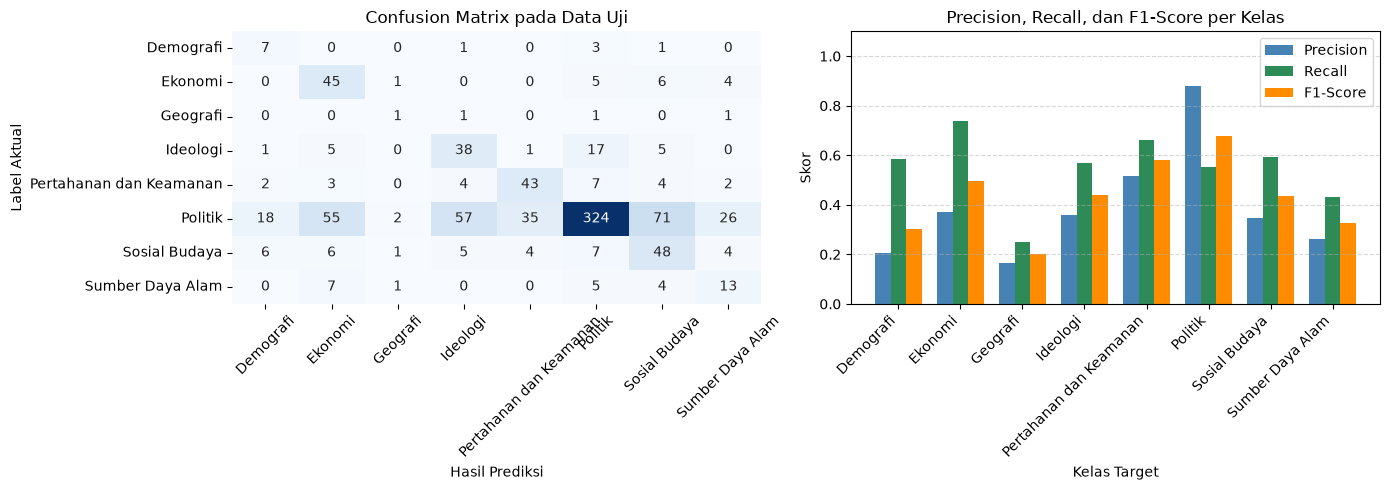

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_cm = pd.DataFrame(cm_test, index=naive_bayes._classes, columns=naive_bayes._classes)
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Confusion Matrix pada Data Uji')
axes[0].set_xlabel('Hasil Prediksi')
axes[0].set_ylabel('Label Aktual')
axes[0].tick_params(axis='x', rotation=45)

x = np.arange(len(naive_bayes._classes))
lebar = 0.25

axes[1].bar(x - lebar, df_metrics_test['Precision'], width=lebar, label='Precision', color='steelblue')
axes[1].bar(x, df_metrics_test['Recall'], width=lebar, label='Recall', color='seagreen')
axes[1].bar(x + lebar, df_metrics_test['F1-Score'], width=lebar, label='F1-Score', color='darkorange')

axes[1].set_title('Precision, Recall, dan F1-Score per Kelas')
axes[1].set_xlabel('Kelas Target')
axes[1].set_ylabel('Skor')
axes[1].set_xticks(x)
axes[1].set_xticklabels(naive_bayes._classes, rotation=45, ha='right')
axes[1].set_ylim(0, 1.1)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

---

## 7. Graphical User Interface (GUI)

In [57]:
import tkinter as tk

def ubah_teks_ke_vektor(teks):
    teks_bersih = clean_caracter(teks)
    teks_bersih = saring_kata_umum(teks_bersih)
    teks_bersih = ubah_kata_dasar(teks_bersih)

    vektor = ubah_ke_tfidf([teks_bersih], kamus_kata, skor_idf)
    return np.asarray(vektor, dtype=np.float64)

def prediksi_teks():
    teks = input_teks.get("1.0", tk.END).strip()
    if not teks:
        label_hasil.config(text="Silakan masukkan teks terlebih dahulu!")
        return

    x_vektor = ubah_teks_ke_vektor(teks)
    kelas_prediksi = naive_bayes.predict(x_vektor)[0]
    probabilitas = naive_bayes.predict_probabilities(x_vektor)[0]
    keyakinan = np.max(probabilitas) * 100

    label_hasil.config(text=f"Hasil Prediksi: {kelas_prediksi} ({keyakinan:.2f}%)")

    
def reset_teks():
    input_teks.delete("1.0", tk.END)
    label_hasil.config(text="Hasil Prediksi: -")

root = tk.Tk()
root.title("Klasifikasi Teks Naive Bayes Multinomial")
root.geometry("550x480")
root.configure(padx=15, pady=15)

tk.Label(root, text="KLASIFIKASI TEKS NAIVE BAYES", font=("Arial", 13, "bold")).pack(pady=(0, 5))

tk.Label(root, text="Masukkan Teks / Komentar:", font=("Arial", 10, "bold"), anchor="w").pack(fill="x")
input_teks = tk.Text(root, height=4, font=("Arial", 10), wrap="word")
input_teks.pack(fill="x", pady=5)

frame_tombol = tk.Frame(root)
frame_tombol.pack(pady=5)
tk.Button(frame_tombol, text="Prediksi", command=prediksi_teks, width=12, bg="#1e88e5", fg="white", font=("Arial", 10, "bold")).pack(side="left", padx=5)
tk.Button(frame_tombol, text="Reset", command=reset_teks, width=12, bg="#e53935", fg="white", font=("Arial", 10, "bold")).pack(side="left", padx=5)

label_hasil = tk.Label(root, text="Hasil Prediksi: -", font=("Arial", 11, "bold"), fg="#0d47a1", pady=8)
label_hasil.pack()

root.mainloop()

---

## 8. Conclusion

Berdasarkan seluruh rangkaian analisis data, pemrosesan awal, pembangunan model, hingga evaluasi yang telah dijalankan, diperoleh beberapa kesimpulan utama sebagai berikut:

1. Dataset awal yang berjumlah 5.000 baris dan 2 kolom (text dan label) tidak memiliki nilai kosong (missing value), namun mengalami ketidakseimbangan kelas pada 8 kategori. Setelah melalui penghapusan data duplikat, pembersihan atribut media sosial, normalisasi kata tidak baku, penyaringan stopwords, serta stemming, dihasilkan 4.538 baris data bersih. [Lihat pengecekan data](#25-memriksa-jumlah-data-missing-value-dan-data-duplikat) 

2. Pada tahap preprocessing, data bersih dibagi secara proporsional (stratified splitting) menjadi 3.630 data latih (80%) dan 908 data uji (20%). Seluruh teks kemudian dikonversi ke matriks numerik TF-IDF berdimensi 5.000 fitur dengan normalisasi dan diseimbangkan menggunakan random oversampling menjadi 18.816 data latih (2.352 data per kelas) agar model dapat belajar secara optimal. [Lihat pemrosesan data](#41-menangani-data-duplikat-identik)

3. Model Multinomial Naive Bayes berhasil dibangun untuk mengklasifikasikan teks ke dalam 8 kategori. Representasi fitur menggunakan 5.000 kosakata TF-IDF, sedangkan *random oversampling* diterapkan pada data latih sehingga jumlah sampel setiap kelas menjadi seimbang. Model memperoleh akurasi sebesar **75,21%** pada data latih dan **57,16%** pada data uji, dengan *weighted F1-score* data uji sebesar **60,03%** dan *macro F1-score* sebesar **43,22%**. Perbedaan performa antara data latih dan data uji menunjukkan bahwa kemampuan generalisasi model masih perlu ditingkatkan. Performa antar kelas juga belum merata; kelas dengan jumlah data uji yang sedikit, seperti `Geografi`, memperoleh *F1-score* yang lebih rendah dibandingkan kelas `Politik`.

4. Secara keseluruhan, model dan GUI telah membentuk alur klasifikasi teks yang dapat digunakan untuk mencoba masukan baru. Namun, nilai evaluasi pada data uji menunjukkan masih terdapat ruang untuk meningkatkan akurasi dan keseimbangan performa pada seluruh kategori, terutama pada kelas dengan jumlah sampel yang terbatas.